# KIKA Tutorial: MCTAL File

This tutorial explores the functionality of KIKA for working with MCNP MCTAL output files. We'll cover how to:

- Parse and examine MCNP MCTAL files
- Work with tallies and their bins
- Get labelled data as xarray Datasets and pandas DataFrames
- Select slices and read the total bins (energy-integrated results)
- Visualize tally convergence (TFC)
- Analyze perturbation data

FMESH mesh tallies are not in MCTAL; they are read with `kika.read_meshtal` (see the *Mesh tallies* tutorial in the documentation).

Let's start by importing the necessary modules and loading example MCTAL files.

In [1]:
import kika
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Setup paths
repo_root = Path.cwd().resolve().parent
data_dir = repo_root / 'examples' / 'data'

# Load example MCTAL files
mctal_file3 = data_dir / 'mctalfile_example_3.m'  # For general features
mctal_file1 = data_dir / 'mctalfile_example_1.m'  # For TFC and perturbations

## 1. Basic MCTAL File Parsing

Let's start by parsing an MCNP MCTAL file and exploring the basic structure.

In [2]:
# Parse the first MCTAL file
mctal_data3 = kika.read_mctal(mctal_file3)

# Display basic information about the MCTAL file
mctal_data3

<Mctal mcnp6 6 03/21/25 09:04:37: nps=110079, 33 tallies, kcode>
  Example 3 MODEL
  <Tally 10014 (cell flux, n) 'Reaction rate 58Ni(n,p)  (Vol.) in (-1,+2)': cell=1, segment=7, energy=4+total>
  <Tally 10024 (cell flux, n) 'Reaction rate 58Ni(n,p)  (Vol.) in (-1,-1)': cell=1, segment=7>
  <Tally 10034 (cell flux, n) 'Reaction rate 58Ni(n,p)  (Vol.) in (-29,+2)': cell=1, segment=22>
  <Tally 10044 (cell flux, n) 'Reaction rate 58Ni(n,p)  (Vol.) in (-29,-2)': cell=1, segment=7>
  <Tally 10054 (cell flux, n) 'Reaction rate 58Ni(n,p)  (Vol.) in (-29,-7)': cell=1, segment=7>
  <Tally 10064 (cell flux, n) 'Reaction rate 58Ni(n,p)  (Vol.) in (-29,-12)': cell=1, segment=7>
  <Tally 10074 (cell flux, n) 'Reaction rate 58Ni(n,p)  (Vol.) in (-27,-14)': cell=1, segment=7>
  <Tally 10084 (cell flux, n) 'Reaction rate 58Ni(n,p)  (Vol.) in (-22,-14)': cell=1, segment=7>
  <Tally 10094 (cell flux, n) 'Reaction rate 58Ni(n,p)  (Vol.) in (-17,-14)': cell=1, segment=7>
  <Tally 10104 (cell flux, n) 'Rea

### MCTAL File Structure

The parsed MCTAL file is represented by a `Mctal` object containing:

- Header information (code name, version, problem id, etc.)
- Number of tallies and perturbations
- Tally data organized by tally ID
- Detailed information about tally types

In [3]:
# Header information
print(f"Code: {mctal_data3.code} {mctal_data3.version}")
print(f"Problem ID: {mctal_data3.probid}")
print(f"Number of particle histories: {mctal_data3.nps:.2e}")
print(f"Problem Title: {mctal_data3.title}")

# Tally information
print(f"\nNumber of tallies: {len(mctal_data3)}")
print(f"Tally numbers: {mctal_data3.tally_numbers}")

Code: mcnp6 6
Problem ID: 03/21/25 09:04:37
Number of particle histories: 1.10e+05
Problem Title: Example 3 MODEL

Number of tallies: 33
Tally numbers: [10014, 10024, 10034, 10044, 10054, 10064, 10074, 10084, 10094, 10104, 10114, 10124, 10134, 10144, 10154, 10164, 10174, 10184, 10194, 10204, 10214, 10224, 10234, 10244, 10254, 10264, 10274, 10284, 10294, 10304, 20014, 20024, 20234]


## 2. Working with Tallies

Tallies are the main output of MCNP simulations. The `Mctal` class provides access to all tallies in the MCTAL file, each represented by a `Tally` object.

In [4]:
# All tally numbers, in file order
tally_ids = mctal_data3.tally_numbers
print(f"Available tally IDs: {tally_ids}")

# Access a tally by its number
tally_id = tally_ids[0]
tally = mctal_data3[tally_id]
display(tally)

Available tally IDs: [10014, 10024, 10034, 10044, 10054, 10064, 10074, 10084, 10094, 10104, 10114, 10124, 10134, 10144, 10154, 10164, 10174, 10184, 10194, 10204, 10214, 10224, 10234, 10244, 10254, 10264, 10274, 10284, 10294, 10304, 20014, 20024, 20234]


<Tally 10014 (cell flux, n) 'Reaction rate 58Ni(n,p)  (Vol.) in (-1,+2)': cell=1, segment=7, energy=4+total>

### Accessing Tally Data

MCNP writes a tally as an array over eight bin axes (`f d u s m c e t`). `tally.result` and `tally.error` hold that array exactly as written, total bins included, and `tally.axes` describes each axis.

In [5]:
tally = mctal_data3[tally_ids[0]]

print(f"Tally comment (FC card): {tally.comment}")
print(f"Kind: {tally.kind}, particles: {tally.particles}")
print(f"Raw array shape (f d u s m c e t): {tally.shape}")

# Energy bins, if any (upper bounds, MeV)
if tally.energies is not None:
    print("\nEnergy bin upper bounds:")
    for i, energy in enumerate(tally.energies):
        print(f"  Bin {i}: {energy:.6e} MeV")

Tally comment (FC card): Reaction rate 58Ni(n,p)  (Vol.) in (-1,+2)
Kind: cell flux, particles: ['n']
Raw array shape (f d u s m c e t): (1, 1, 1, 7, 1, 1, 5, 1)

Energy bin upper bounds:
  Bin 0: 1.000000e-01 MeV
  Bin 1: 1.000000e+00 MeV
  Bin 2: 3.000000e+00 MeV
  Bin 3: 2.000000e+01 MeV


## 3. Labelled Data: xarray and DataFrames

`to_xarray()` returns one named dimension per binned axis, without the total bins; `to_dataframe()` flattens it to one row per bin.

In [6]:
tally = mctal_data3[tally_ids[0]]

tally_df = tally.to_dataframe()
print("Tally data as DataFrame:")
display(tally_df)

Tally data as DataFrame:


,cell,segment,energy,result,error,energy_low
0,22002,1,0.1,0.0,0.0000,0.0
1,22002,1,1.0,150578.0,0.7105,0.1
2,22002,1,3.0,8901150.0,0.5135,1.0
3,22002,1,20.0,51558600.0,0.7182,3.0
4,22002,2,0.1,0.0,0.0000,0.0
5,22002,2,1.0,111063.0,0.7287,0.1
6,22002,2,3.0,66178300.0,0.6156,1.0
7,22002,2,20.0,0.0,0.0000,3.0
8,22002,3,0.1,0.0,0.0000,0.0
9,22002,3,1.0,214811.0,0.3045,0.1


## 4. Working with Multidimensional Data

The xarray Dataset carries the bin labels as coordinates: cell numbers, segment indices, and the upper bounds of energy bins (with their lower bounds in `energy_low`).

In [7]:
tally = mctal_data3[tally_ids[0]]

ds = tally.to_xarray()
print("Tally data as xarray Dataset:")
display(ds)

Tally data as xarray Dataset:


<xarray.Dataset> Size: 576B
Dimensions:     (cell: 1, segment: 7, energy: 4)
Coordinates:
  * cell        (cell) int64 8B 22002
  * segment     (segment) int64 56B 1 2 3 4 5 6 7
  * energy      (energy) float64 32B 0.1 1.0 3.0 20.0
    energy_low  (energy) float64 32B 0.0 0.1 1.0 3.0
Data variables:
    result      (cell, segment, energy) float64 224B 0.0 1.506e+05 ... 5.659e+07
    error       (cell, segment, energy) float64 224B 0.0 0.7105 ... 0.7575
Attributes:
    tally:    10014
    kind:     cell flux
    comment:  Reaction rate 58Ni(n,p)  (Vol.) in (-1,+2)

### Extracting Slices of Multidimensional Data

Use xarray's `sel` (by label) and `isel` (by position) to extract slices.

In [8]:
tally = mctal_data3[tally_ids[0]]
ds = tally.to_xarray()
print(f"Dimensions of tally {tally.id}: {dict(ds.sizes)}")

# One energy bin, selected by its upper bound
energy = float(ds.energy[2])
print(f"\nResults for the energy bin ending at {energy} MeV:")
display(ds.sel(energy=energy).to_dataframe())

# One segment (segments are numbered from 1)
print("\nResults for segment 2:")
display(ds.sel(segment=2).to_dataframe())

Dimensions of tally 10014: {'cell': 1, 'segment': 7, 'energy': 4}

Results for the energy bin ending at 3.0 MeV:


result   error  energy  energy_low
cell  segment                                        
22002 1         8901150.0  0.5135     3.0         1.0
      2        66178300.0  0.6156     3.0         1.0
      3        26666300.0  0.3549     3.0         1.0
      4        43900100.0  0.6623     3.0         1.0
      5        70412600.0  0.3141     3.0         1.0
      6        33045500.0  0.7646     3.0         1.0
      7        42515400.0  0.4196     3.0         1.0


Results for segment 2:


result   error  segment  energy_low
cell  energy                                         
22002 0.1            0.0  0.0000        2         0.0
      1.0       111063.0  0.7287        2         0.1
      3.0     66178300.0  0.6156        2         1.0
      20.0           0.0  0.0000        2         3.0

### Working with Total Bins (Energy-Integrated Data)

When a bin card asks for a total (`et`, `st`, `tt`...), MCNP appends a total bin. `tally.total(...)` returns it as a Dataset over the remaining axes.

In [9]:
tally = mctal_data3[tally_ids[0]]

integral = tally.total("energy")
print("Energy-integrated data:")
display(integral)
display(integral.to_dataframe())

Energy-integrated data:


<xarray.Dataset> Size: 176B
Dimensions:  (cell: 1, segment: 7)
Coordinates:
  * cell     (cell) int64 8B 22002
  * segment  (segment) int64 56B 1 2 3 4 5 6 7
Data variables:
    result   (cell, segment) float64 56B 6.061e+07 6.629e+07 ... 9.92e+07
    error    (cell, segment) float64 56B 0.6156 0.6146 0.283 ... 0.6997 0.4681
Attributes:
    tally:       10014
    kind:        cell flux
    comment:     Reaction rate 58Ni(n,p)  (Vol.) in (-1,+2)
    total_over:  ['energy']

result   error
cell  segment                     
22002 1         60610300.0  0.6156
      2         66289300.0  0.6146
      3        131235000.0  0.2830
      4         83685700.0  0.4887
      5        248358000.0  0.2721
      6         93375700.0  0.6997
      7         99200200.0  0.4681

## 5. Visualizing Tally Convergence with TFC Data

KIKA provides visualization tools for Tally Fluctuation Chart (TFC) data, which shows how simulation results converge with increasing particle histories. For this section, we'll use `mctalfile_example_1.m` which contains TFC data.

MCTAL file with TFC data:


<Mctal mcnp6 6 05/24/24 17:18:48: nps=10000000, 1 tallies, 1760 perturbations>
  attenuation Sphere for PWR
  <Tally 4 (cell flux, n) 'shell Detector': cell=1, energy=3+total, 1760 perturbations>


Tally 4 has 20 TFC data points


,nps,result,error,fom
0,512000,1.155110e-08,0.025720,23.1291
1,1024000,1.129350e-08,0.018320,22.8261
2,1536000,1.111460e-08,0.014942,22.8840
3,2048000,1.121930e-08,0.012906,23.0048
4,2560000,1.116230e-08,0.011506,23.1591


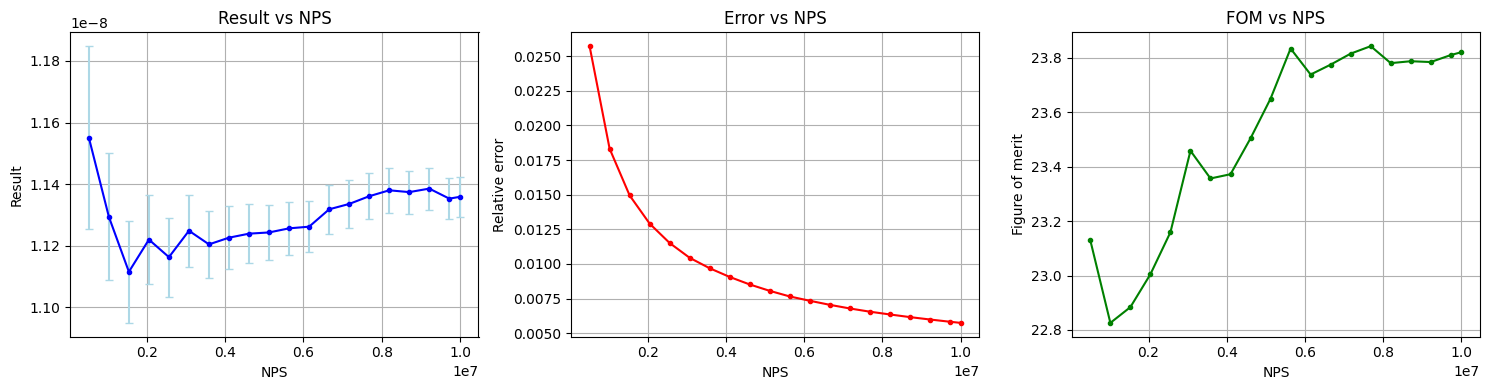

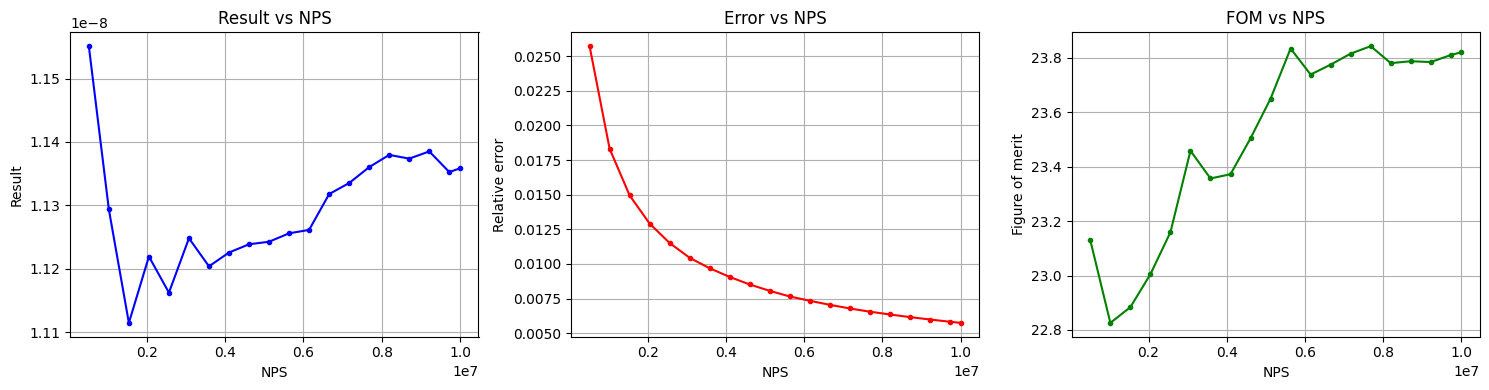

In [10]:
# Load the MCTAL file with TFC and perturbation data
mctal_data1 = kika.read_mctal(mctal_file1)
print("MCTAL file with TFC data:")
display(mctal_data1)

tally = mctal_data1[mctal_data1.tally_numbers[0]]
tfc = tally.tfc

print(f"\nTally {tally.id} has {len(tfc.nps)} TFC data points")
display(tfc.to_dataframe().head())

# Plot result, relative error and figure of merit against NPS
tfc.plot(figsize=(15, 4))
plt.show()

# Without error bars, for a clearer view of the trend
tfc.plot(figsize=(15, 4), show_error_bars=False)
plt.show()

## 6. Working with Perturbations

MCNP perturbation data allows users to estimate the sensitivity of a tally to changes in cross-sections or material densities. KIKA provides tools to analyze this data efficiently. We'll continue using `mctalfile_example_1.m` which contains perturbation data.

In [11]:
tally = mctal_data1[mctal_data1.tally_numbers[0]]

# Perturbations are keyed by PERT card number
pert_ids = sorted(tally.perturbations)
print(f"Tally {tally.id} has {len(pert_ids)} perturbations: {pert_ids[0]} ... {pert_ids[-1]}")

Tally 4 has 1760 perturbations: 1 ... 1760


In [12]:
# A perturbation has the shape of the unperturbed tally; the same views take its number
pert_id = pert_ids[0]
display(tally.to_xarray(perturbation=pert_id))
display(tally.total("energy", perturbation=pert_id))

<xarray.Dataset> Size: 104B
Dimensions:     (cell: 1, energy: 3)
Coordinates:
  * cell        (cell) int64 8B 10
  * energy      (energy) float64 24B 0.1 1.0 3.0
    energy_low  (energy) float64 24B 0.0 0.1 1.0
Data variables:
    result      (cell, energy) float64 24B 0.0 0.0 0.0
    error       (cell, energy) float64 24B 0.0 0.0 0.0
Attributes:
    tally:         4
    kind:          cell flux
    comment:       shell Detector
    perturbation:  1

<xarray.Dataset> Size: 24B
Dimensions:  (cell: 1)
Coordinates:
  * cell     (cell) int64 8B 10
Data variables:
    result   (cell) float64 8B 0.0
    error    (cell) float64 8B 0.0
Attributes:
    tally:         4
    kind:          cell flux
    comment:       shell Detector
    perturbation:  1
    total_over:    ['energy']

### Converting Perturbation Data to DataFrames

Every view accepts `perturbation=`, so a table over several perturbations is a concatenation:

In [13]:
import pandas as pd

frames = [tally.to_dataframe(perturbation=p).assign(perturbation=p) for p in pert_ids[:5]]
pert_df = pd.concat(frames, ignore_index=True)
print("First five perturbations as one DataFrame:")
display(pert_df)

print("\nPerturbation 420 as DataFrame:")
display(tally.to_dataframe(perturbation=420))

First five perturbations as one DataFrame:


,cell,energy,result,error,energy_low,perturbation
0,10,0.1,0.000000e+00,0.0000,0.0,1
1,10,1.0,0.000000e+00,0.0000,0.1,1
2,10,3.0,0.000000e+00,0.0000,1.0,1
3,10,0.1,0.000000e+00,0.0000,0.0,2
4,10,1.0,0.000000e+00,0.0000,0.1,2
5,10,3.0,0.000000e+00,0.0000,1.0,2
6,10,0.1,2.643730e-09,0.0117,0.0,3
7,10,1.0,7.648100e-09,0.0071,0.1,3
8,10,3.0,1.066520e-09,0.0173,1.0,3
9,10,0.1,2.643730e-09,0.0117,0.0,4



Perturbation 420 as DataFrame:


,cell,energy,result,error,energy_low
0,10,0.1,-1.811390e-10,0.1711,0.0
1,10,1.0,-7.793140e-10,0.0841,0.1
2,10,3.0,-3.828780e-11,0.7584,1.0


## 7. Summary

In this tutorial, we've explored the KIKA functionality for working with MCNP MCTAL output files:

1. **Basic MCTAL Parsing**: `kika.read_mctal`, the header and the tally list
2. **Working with Tallies**: `mctal[number]`, the raw eight-axis array and its axes
3. **Labelled data**: `to_xarray()` and `to_dataframe()`, slicing with `sel`
4. **Totals**: `total("energy")` and the other total bins
5. **TFC Visualization**: `tally.tfc.plot()`
6. **Perturbation Analysis**: the same views with `perturbation=`